# LLM-Refactoring Energy Analysis

Raw per-run `codecarbon` measurements (not just medians) comparing **human**
(the original LeetCode-style baseline, `src/data/human/`) against **claude**
(Claude Code's energy-focused refactor of the same 17 problems x 3 languages,
`Results/code/claude/`), produced by `src/codecarbon_metrics_from_code.py` and
stored under `Analysis/data/code/<source>/<Problem>/<language>/emissions.csv`.

Research questions answered below:

- **General RQ**: To what extent is it possible to obtain energy-efficient
  code through LLM refactoring?
- **RQ1**: What are the variations in energy efficiency of LLM-refactored
  code across different programming languages (Python, C++, Java)?
- **RQ2**: What is the impact of data structure and algorithmic technique
  choice on the energy efficiency of refactored code?
- **RQ3**: Is the energy efficiency of programs refactored by different LLMs
  (Claude Code, Codex) significantly different?

**Methodology sources, mixed together:**
- The two-level statistical procedure (Mann-Whitney U for independent samples,
  Wilcoxon signed-rank for paired/repeated-measures, Cliff's delta effect
  size, Holm-Bonferroni correction per family) follows
  `codecarbon-analysis/comparison_vs_contemporary_control.ipynb`.
- The choice of *which* test applies to *which* design (independent vs.
  paired, two groups vs. more than two) follows the standard framework taught
  in `codecarbon-analysis/18-Testes de hipótese.pdf` (itself based on Wohlin
  et al., *Experimentation in Software Engineering*, Ch. 10) — summarized in
  the methodology section below.
- Grouping by language/category, the `seaborn` "vlag" diverging heatmap style,
  and loading problem metadata (tags, LeetCode number) reuse this repo's own
  prior `Analysis/AnalysisRQ1.ipynb` / `AnalysisRQ2.ipynb` conventions and
  `src/config/constants.py`.

In [1]:
import itertools
import os
import sys
from dataclasses import dataclass, asdict
from typing import Any, cast

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats

sys.path.insert(0, os.path.abspath("../src"))
from config.constants import (
    PROGRAMS, LANGUAGES, SOURCES, HUMAN, CLAUDE,
    get_codecarbon_output_dir, get_tag_category, TAG_CATEGORIES,
)

sns.set_theme(style="white")
pd.set_option("display.width", 160)

## Load and combine raw runs

Walks every `(problem, language, source)` cell via `PROGRAMS`/`LANGUAGES`/
`SOURCES` from `src/config/constants.py` (the same source of truth
`codecarbon_metrics_from_code.py` used to produce this data), reads each
cell's `emissions.csv`, and tags every row with the problem's metadata
(`leetcode_number`, `categories` — derived from `tags` via
`get_tag_category()`, built from `Sheets/Tasks_and_Tags.xlsx` and
`Sheets/Grouping_of_Tags.xlsx`).

Two groups of columns are kept, for two different purposes:
- **`METRICS`** (`energy_consumed` kWh, `duration` s) — the two headline
  metrics RQ1/RQ2/the General RQ actually run hypothesis tests on below.
  `codecarbon` also reports `emissions` (kg CO2), but that column is
  intentionally not loaded at all: on a single fixed machine, `emissions` is
  just `energy_consumed` multiplied by one constant (the grid's
  carbon-intensity factor), so it carries zero independent information over
  `energy_consumed` and would only duplicate every test below for free.
- **`RESOURCE_COLUMNS`** (`cpu_power`, `gpu_power`, `ram_power` in watts;
  `cpu_energy`, `gpu_energy`, `ram_energy` in kWh) — `codecarbon`'s
  component-level breakdown of where `energy_consumed` comes from (their sum
  is `energy_consumed`). These are loaded and shown in the preview table
  below for a holistic view of what's actually being measured, but — unlike
  `METRICS` — are *not* run through the formal RQ1/RQ2 statistical
  machinery; on this GPU-having machine, `gpu_power`/`gpu_energy` reflect
  system-wide GPU draw during the measurement window, not something either
  `human`'s or `claude`'s CPU-bound code is actually using, so testing them
  the same way as `energy_consumed` would mostly be measuring background
  noise rather than a refactoring effect.

In [2]:
METRICS = ["energy_consumed", "duration"]
METRIC_LABELS = {"energy_consumed": "Energy (kWh)", "duration": "Duration (s)"}
RESOURCE_COLUMNS = ["cpu_power", "gpu_power", "ram_power", "cpu_energy", "gpu_energy", "ram_energy"]

rows, missing = [], []
for program in PROGRAMS:
    for language in LANGUAGES:
        for source in SOURCES:
            path = os.path.join(get_codecarbon_output_dir(program, language, source=source), "emissions.csv")
            if not os.path.isfile(path):
                missing.append((program["name"], language, source))
                continue
            df = pd.read_csv(path)
            df["problem"] = program["name"]
            df["leetcode_number"] = program["leetcode_number"]
            df["language"] = language
            df["source"] = source
            df["categories"] = [tuple(sorted({get_tag_category(t) for t in program["tags"]}))] * len(df)
            keep = ["problem", "leetcode_number", "language", "source", "categories", "run_id"] + METRICS + RESOURCE_COLUMNS
            rows.append(df[keep])

raw = pd.concat(rows, ignore_index=True)
print(f"{raw.shape[0]} runs loaded, {raw.problem.nunique()} problems, {len(missing)} (problem,language,source) cells missing")
raw.groupby(["source", "language"]).size().rename("n_runs").reset_index()

194 runs loaded, 17 problems, 5 (problem,language,source) cells missing


,source,language,n_runs
0,claude,cpp,34
1,claude,java,34
2,claude,python,34
3,human,cpp,34
4,human,java,24
5,human,python,34


In [3]:
# Holistic per-run view: every loaded column, source included, sorted so the
# two conditions for the same problem/language sit next to each other.
raw.sort_values(["problem", "language", "source", "run_id"])[
    ["problem", "language", "source", "run_id"] + METRICS + RESOURCE_COLUMNS
].reset_index(drop=True)

,problem,language,source,run_id,energy_consumed,duration,cpu_power,gpu_power,ram_power,cpu_energy,gpu_energy,ram_energy
0,Find_Edges_in_Shortest_Paths,cpp,claude,07fdadce-b6ca-44f8-84ec-2bba96fccaf6,0.000005,3.731699,8.413331,12.229615,20.0,7.873865e-07,0.000002,0.000002
1,Find_Edges_in_Shortest_Paths,cpp,claude,a79b64f3-2418-44e3-8744-1ed7a5518603,0.000005,3.728372,8.338742,10.737234,20.0,7.585825e-07,0.000002,0.000002
2,Find_Edges_in_Shortest_Paths,cpp,human,13be9dc0-e561-41f6-b40c-f4209f1bf3c0,0.000005,3.766082,8.007906,11.016409,20.0,7.491407e-07,0.000002,0.000002
3,Find_Edges_in_Shortest_Paths,cpp,human,4d8ffe0d-f4f1-4d05-9acd-af4a404c5273,0.000005,4.035410,8.009559,11.112490,20.0,7.595176e-07,0.000002,0.000002
4,Find_Edges_in_Shortest_Paths,java,claude,acde2ce0-1e0b-4f56-a66b-37dca05d0459,0.000148,13.394798,8.188691,12.571880,20.0,2.257664e-05,0.000070,0.000055
...,...,...,...,...,...,...,...,...,...,...,...,...
189,Trapping_Rain_Water,java,human,c19b36c0-c08a-4c62-a2ce-f0813716f9a6,0.000046,6.503951,8.016315,12.959917,20.0,6.906772e-06,0.000022,0.000017
190,Trapping_Rain_Water,python,claude,d45bee70-3e66-4776-8400-c7022aa1ed37,0.000020,4.652089,14.951730,12.222730,20.0,4.483880e-06,0.000008,0.000007
191,Trapping_Rain_Water,python,claude,f9de8b7f-2f7f-4947-9556-36c2900815ef,0.000016,4.526002,8.734413,12.084533,20.0,2.705542e-06,0.000007,0.000006
192,Trapping_Rain_Water,python,human,2fd17675-3c5e-4c7d-9fca-695cacf2ba33,0.000017,4.570756,8.411127,13.375525,20.0,2.569025e-06,0.000008,0.000006


## Data availability and known caveats

**Missing cells — pre-existing compile bugs, not a measurement gap.** The 5
missing cells below are exactly `N-Queens`, `Sudoku_Solver`,
`Merge_k_Sorted_Lists`, `First_Missing_Positive`, and `Permutation_Sequence`
(all `java`, `human`): the original human-written files declare two
top-level `public` classes in one `.java` file, which `javac` rejects
outright — `compile_program()` in `src/utils.py` returns `False` before
`get_codecarbon_output_dir()` is ever called, so no folder/CSV is created for
those cells. This is documented in `Claude_Experiment_Procedure.md`. Claude's
refactor fixed this compile defect (since a file that cannot compile has no
behavior to preserve), so every `claude`/`java` cell has data; only the
`human`/`java` side for these 5 problems is missing.

**One problem's C++ measurements reflect a crash, on both sides.**
`Find_the_Sum_of_Subsequence_Powers.cpp` has a pre-existing stale-cache bug
(its memo table is never cleared between calls) that makes the compiled
binary abort via `assert` partway through every run, on *both* `human` and
`claude` (the refactor deliberately preserved this behavior rather than
"fixing" it — see `Claude_Experiment_Procedure.md`). `codecarbon` still
records energy for a crashed run (the process did consume real energy before
aborting), so this cell's rows are kept for transparency, but they measure a
partial/crashed execution, not a full successful one, on both sides
symmetrically.

**A few cells finish in milliseconds, where measurement noise can dominate.**
Problems whose `main()` has no repetition loop (e.g.
`Find_the_Sum_of_Subsequence_Powers`'s Python variant — see
`Claude_Experiment_Procedure.md`) run and exit almost instantly, so their
absolute energy is tiny enough (~3x10⁻⁸ kWh) that ordinary measurement noise
can swing `delta_percent` by hundreds of percent even with no real change in
behavior (seen as an outlier annotated in the General RQ plot below). The
rank-based tests used throughout this notebook are robust to this (they
don't care about an outlier's exact magnitude, only its sign/rank), but it's
worth knowing before reading any single raw `delta_percent` number for one
of these cells at face value.

**Current sample size is small.** `CODECARBON_RUNS` (in
`src/config/constants.py`) was set to 2 for the run this data comes from,
not the original 10. This matters a lot for the *per-problem* comparisons
(Level 1 below): with exactly 2 runs per side, a two-sided Mann-Whitney U
test has only 3 possible p-values (1.0, 0.667, 0.333) — **it is
mathematically impossible for any single per-problem comparison to reach
p < 0.05 at this sample size**, regardless of the true effect. The
group-level comparisons (Level 2 — pooling across many problems) still have
real power (n=12-17 problems per language, more per category), which is
where this notebook's significant findings come from. Re-running
`codecarbon_metrics_from_code.py` with a larger `CODECARBON_RUNS` (e.g. the
original 10) would let the per-problem level detect real effects too.

In [4]:
print("Missing cells:")
for m in missing:
    print(" ", m)

cell_counts = raw.groupby(["problem", "language", "source"]).size()
print(f"\nRuns per (problem, language, source) cell: {sorted(cell_counts.unique())} (all cells have the same n)")

Missing cells:
  ('N-Queens', 'java', 'human')
  ('Sudoku_Solver', 'java', 'human')
  ('Merge_k_Sorted_Lists', 'java', 'human')
  ('First_Missing_Positive', 'java', 'human')
  ('Permutation_Sequence', 'java', 'human')

Runs per (problem, language, source) cell: [np.int64(2)] (all cells have the same n)


## How to read these results (plain-language glossary)

- **`delta_percent`** — the headline number: how much higher (positive) or
  lower (negative) the metric is for `claude` compared to `human`, as a
  percentage of the `human` median. `-6.17%` for energy means "Claude's
  refactor used 6.17% less energy than the human original, on this group."
- **`significant` (yes/no)** — whether that percentage is trustworthy or
  could be noise, based on `p_value_holm` (see below), **not** the raw
  `p_value`. "No" means *inconclusive*, not "no effect" — with few runs per
  group, a real but modest effect can easily fail to clear the bar.
- **`p_value_holm`** — the Holm-Bonferroni-corrected p-value. Several
  comparisons are run side by side in every table here (several languages,
  several categories); testing many things at once makes some look
  "significant" by chance alone, so Holm raises the bar. This — not the raw
  `p_value` — is what `significant` is computed from.
- **`cliffs_delta`** / **`effect_magnitude`** — not "is there a difference"
  but "how big and how consistent is it," on a −1..+1 scale, bucketed into
  negligible / small / medium / large (Romano et al., 2006 thresholds).
  Negative = `claude` tends lower (better); positive = `claude` tends higher.
- **`distribution_normal`** — reported for transparency only (see
  methodology below); it doesn't change how any other column is computed.
- **`mannwhitney_u` / `wilcoxon_stat`, `n_baseline`/`n_variant`/`n_problems`**
  — the intermediate numbers the test is built from; useful only to
  double-check the arithmetic, not needed to read the conclusions.

## Statistical methodology

**Hypotheses.** H0 = Claude's refactor makes no real difference to the
metric; Ha = it does. Significance level α = 0.05 throughout.

**Two-level design (this is the one deliberate departure from the reference
notebook, and the reason for it):** the reference notebook pools several
*variants of the same artifact* (same absolute scale) when testing a group,
so it can always compare raw metric values directly with Mann-Whitney U. Here,
RQ1 and RQ2 each pool **17 different problems** with wildly different
absolute energy/duration scales (an O(n²) backtracking problem and an O(1)
lookup aren't on the same scale at all) — pooling their raw values directly
would let "which problem is it" swamp "human vs. claude" as the dominant
source of variation. The fix, and the reason this notebook has two levels
instead of one:

1. **Level 1 — per `(problem, language)`, `human` vs. `claude` runs.** Each
   problem's own `human` runs and `claude` runs are genuinely independent
   samples (no run of `human` is paired with a specific run of `claude` —
   they're just repeated measurements under each condition), so this is the
   textbook "one factor, two treatments, independent samples" design →
   **Mann-Whitney U**, exactly as the reference notebook and
   `18-Testes de hipótese.pdf` (Wohlin et al., Ch. 10) both prescribe for
   that design. Holm-corrected within each `(language, metric)` family (all
   problems sharing a language, never mixed across languages).
2. **Level 2 — pooling `delta_percent` across problems within a group**
   (a language, for RQ1; a category, for RQ2). Here each *problem*
   contributes exactly one paired observation (its own `human` value and its
   own `claude` value) — the textbook "one factor, two treatments, **paired**
   comparison" design, for which both the reference material and
   `18-Testes de hipótese.pdf` prescribe the **Wilcoxon signed-rank test**
   (the paired counterpart to Mann-Whitney U) instead — here applied to
   `delta_percent` against a null of 0 (no change). Holm-corrected within
   each `metric` family (all languages, or all categories, for that metric).

**Normality.** Shapiro-Wilk is computed for every two-sample comparison and
reported in `distribution_normal`, but — like the reference notebook — never
used to switch which test runs: Mann-Whitney U and Wilcoxon are already the
correct choice whenever data isn't normal (the common case with ~2 runs per
group), and using one consistent test keeps every comparison in this
notebook built the same way. Shapiro-Wilk needs n≥3, so with the current
`CODECARBON_RUNS=2`, Level 1's `distribution_normal` is always
"not applicable (n<3)".

**Effect size.** Cliff's delta (`δ = 2U/(n₁·n₂) - 1`) for every two-sample
(Mann-Whitney) comparison, bucketed via Romano et al. (2006): negligible
(|δ|<0.147), small (<0.33), medium (<0.474), large (≥0.474). For Level 2
(one-sample Wilcoxon against 0), there's no two-sample U to build a Cliff's
delta from, so the group tables report `median_delta_percent` and
`n_problems_reduced` instead, which answer the same "how big and how
consistent" question for a one-sample test.

**Multiple comparisons.** Holm-Bonferroni step-down correction, applied
*within* each family as described above — never across families answering a
different question (e.g. RQ1's language families are corrected separately
from RQ2's category families).

**Why pairwise tests instead of a single omnibus test** (relevant for RQ1's
3 languages and RQ2's 16 categories): a Kruskal-Wallis test (the
non-parametric one-way ANOVA — see `18-Testes de hipótese.pdf`) would only
answer "is there *some* difference among these groups," not which one or how
large. Running Mann-Whitney/Wilcoxon pairwise with Holm correction answers
both at once, at the cost of lower power per individual comparison — which
is exactly why RQ1's own language-vs-language pairwise comparisons below
come back non-significant even though some individual languages show a
significant pooled effect vs. their own baseline.

**Current power caveat** (restated from the data-availability section
above): per-problem (Level 1) significance is mathematically unreachable at
`CODECARBON_RUNS=2`. Every "significant" finding in this notebook comes from
Level 2 (pooling many problems), where the sample size is the *problem
count*, not the run count.

In [5]:
ALPHA = 0.05
EFFECT_THRESHOLDS = [(0.147, "negligible"), (0.33, "small"), (0.474, "medium")]

def effect_magnitude(delta):
    m = abs(delta)
    for threshold, label in EFFECT_THRESHOLDS:
        if m < threshold:
            return label
    return "large"

@dataclass
class GroupComparison:
    group: str; metric: str; n_baseline: int; n_variant: int
    baseline_median: float; variant_median: float; delta_percent: float
    shapiro_p_baseline: Any; shapiro_p_variant: Any; distribution_normal: str
    mannwhitney_u: float; p_value: float; cliffs_delta: float; effect_magnitude: str
    p_value_holm: Any = None; significant: Any = None

def shapiro_p(values):
    """Shapiro-Wilk p-value, or None when n < 3 (the test isn't defined)."""
    values = pd.Series(values).dropna()
    return float(stats.shapiro(values).pvalue) if len(values) >= 3 else None

def compare_groups(group, metric, baseline_values, variant_values):
    """Mann-Whitney U + Cliff's delta between two independent samples."""
    b, v = pd.Series(baseline_values).dropna(), pd.Series(variant_values).dropna()
    n_b, n_v = len(b), len(v)
    b_med, v_med = b.median(), v.median()
    delta_pct = (v_med - b_med) / b_med * 100 if b_med != 0 else float("nan")
    p_b, p_v = shapiro_p(b), shapiro_p(v)
    normal = "not applicable (n<3)" if (p_b is None or p_v is None) else ("normal" if (p_b > ALPHA and p_v > ALPHA) else "not normal")
    mwu = cast(Any, stats.mannwhitneyu(v, b, alternative="two-sided"))
    u, p = float(mwu.statistic), float(mwu.pvalue)
    delta = 2 * u / (n_b * n_v) - 1
    return GroupComparison(group, metric, n_b, n_v, b_med, v_med, delta_pct, p_b, p_v, normal, u, p, float(delta), effect_magnitude(delta))

def holm_correction(p_values):
    """Holm-Bonferroni step-down correction; returns adjusted p-values in the same order as p_values."""
    m = len(p_values)
    order = sorted(range(m), key=lambda i: p_values[i])
    adjusted, running_max = [0.0] * m, 0.0
    for rank, idx in enumerate(order):
        running_max = max(running_max, p_values[idx] * (m - rank))
        adjusted[idx] = min(running_max, 1.0)
    return adjusted

def apply_holm_and_significance(comparisons, alpha=ALPHA):
    for c, p_holm in zip(comparisons, holm_correction([c.p_value for c in comparisons])):
        c.p_value_holm = p_holm
        c.significant = "yes" if p_holm < alpha else "no"
    return comparisons

def stats_table(comparisons):
    return pd.DataFrame([asdict(c) for c in comparisons])

def build_per_problem_stats(df, metrics):
    """Level 1: Mann-Whitney U per (problem, language), Holm-corrected within each (language, metric) family."""
    all_comparisons = []
    for metric in metrics:
        for language, lang_df in df.groupby("language"):
            family = []
            for problem, g in lang_df.groupby("problem"):
                b, v = g[g.source == HUMAN][metric], g[g.source == CLAUDE][metric]
                if b.empty or v.empty:
                    continue
                family.append(compare_groups(f"{problem}|{language}", metric, b, v))
            apply_holm_and_significance(family)
            all_comparisons.extend(family)
    table = stats_table(all_comparisons)
    table[["problem", "language"]] = table["group"].str.split("|", expand=True)
    return table.drop(columns=["group"])

def pooled_group_effect(per_problem_df, group_col, group_values_fn, metrics):
    """Level 2: Wilcoxon signed-rank of per-problem delta_percent vs 0, one group per
    group_values_fn(problem) (a list, so one problem can belong to several groups --
    needed for RQ2, where a problem can carry several tag categories). Holm-corrected
    within each metric family."""
    exploded = per_problem_df.copy()
    exploded["_g"] = exploded["problem"].map(group_values_fn)
    exploded = exploded.explode("_g").rename(columns={"_g": group_col})
    records = []
    for metric in metrics:
        family_rows = []
        sub = exploded[exploded.metric == metric]
        for group, g in sub.groupby(group_col):
            deltas = g["delta_percent"].dropna().to_numpy()
            if len(deltas) == 0:
                continue
            try:
                w_stat, p_value = stats.wilcoxon(deltas) if np.any(deltas != 0) else (float("nan"), float("nan"))
            except ValueError:
                w_stat, p_value = float("nan"), float("nan")
            family_rows.append({
                group_col: group, "metric": metric, "n_problems": len(deltas),
                "median_delta_percent": float(np.median(deltas)),
                "n_problems_reduced": int((deltas < 0).sum()),
                "wilcoxon_stat": w_stat, "p_value": p_value,
            })
        pvals = [r["p_value"] for r in family_rows]
        valid = [i for i, p in enumerate(pvals) if not np.isnan(p)]
        for i, p_holm in zip(valid, holm_correction([pvals[i] for i in valid]) if valid else []):
            family_rows[i]["p_value_holm"] = p_holm
            family_rows[i]["significant"] = "yes" if p_holm < ALPHA else "no"
        for r in family_rows:
            r.setdefault("p_value_holm", float("nan")); r.setdefault("significant", "n/a")
        records.extend(family_rows)
    return pd.DataFrame(records)

def pairwise_on_deltas(per_problem_df, group_col, groups, metrics):
    """Direct group-vs-group (never vs. human baseline) Mann-Whitney U on the
    per-problem delta_percent arrays -- answers "does the SIZE of the
    refactoring effect differ between these groups," Holm-corrected within
    each metric family."""
    all_comparisons = []
    for metric in metrics:
        family = []
        sub = per_problem_df[per_problem_df.metric == metric]
        for g1, g2 in itertools.combinations(groups, 2):
            d1, d2 = sub[sub[group_col] == g1]["delta_percent"], sub[sub[group_col] == g2]["delta_percent"]
            if d1.empty or d2.empty:
                continue
            family.append(compare_groups(f"{g1} vs {g2}", metric, d1, d2))
        apply_holm_and_significance(family)
        all_comparisons.extend(family)
    return stats_table(all_comparisons).rename(columns={"group": "comparison"})

per_problem_stats = build_per_problem_stats(raw, METRICS)
# All 46 (problem, language) cells for energy -- not a preview, every row from
# Level 1. (See RQ1/RQ2 below for emissions/duration and for the pooled view.)
per_problem_stats[per_problem_stats.metric == "energy_consumed"].sort_values("delta_percent").reset_index(drop=True)

,metric,n_baseline,n_variant,baseline_median,variant_median,delta_percent,shapiro_p_baseline,shapiro_p_variant,distribution_normal,mannwhitney_u,p_value,cliffs_delta,effect_magnitude,p_value_holm,significant,problem,language
0,energy_consumed,2,2,1.186513e-04,1.151585e-05,-90.294376,None,None,not applicable (n<3),0.0,0.333333,-1.0,large,1.0,no,Sudoku_Solver,python
1,energy_consumed,2,2,1.646465e-05,6.251543e-06,-62.030502,None,None,not applicable (n<3),0.0,0.333333,-1.0,large,1.0,no,Sudoku_Solver,cpp
2,energy_consumed,2,2,6.877720e-05,2.815977e-05,-59.056535,None,None,not applicable (n<3),0.0,0.333333,-1.0,large,1.0,no,Find_the_Sum_of_Subsequence_Powers,java
3,energy_consumed,2,2,1.581521e-04,6.819346e-05,-56.881098,None,None,not applicable (n<3),0.0,0.333333,-1.0,large,1.0,no,Regular_Expression_Matching,java
4,energy_consumed,2,2,5.197019e-06,2.345654e-06,-54.865387,None,None,not applicable (n<3),0.0,0.333333,-1.0,large,1.0,no,Permutation_Sequence,cpp
5,energy_consumed,2,2,1.096673e-04,6.166431e-05,-43.771494,None,None,not applicable (n<3),0.0,0.333333,-1.0,large,1.0,no,Find_Number_of_Coins_to_Place_in_Tree_Nodes,java
6,energy_consumed,2,2,1.477427e-04,9.051323e-05,-38.735892,None,None,not applicable (n<3),0.0,0.333333,-1.0,large,1.0,no,Merge_k_Sorted_Lists,python
7,energy_consumed,2,2,1.430070e-05,8.956321e-06,-37.371444,None,None,not applicable (n<3),0.0,0.333333,-1.0,large,1.0,no,Sorted_GCD_Pair_Queries,cpp
8,energy_consumed,2,2,5.489293e-08,3.871852e-08,-29.465382,None,None,not applicable (n<3),1.0,0.666667,-0.5,large,1.0,no,Length_of_the_Longest_Increasing_Path,python
9,energy_consumed,2,2,1.661908e-05,1.197544e-05,-27.941634,None,None,not applicable (n<3),0.0,0.333333,-1.0,large,1.0,no,Minimum_Window_Substring,cpp


## General RQ — to what extent does LLM refactoring achieve energy-efficient code?

Pools every `(problem, language)` cell's `delta_percent` (46 cells: 17
problems x 3 languages, minus the 5 missing `human`/`java` cells) into one
Wilcoxon signed-rank test per metric against a null of "no change" — the
broadest, least granular cut in this notebook, meant only to answer the
headline question before RQ1/RQ2 break it down.

In [6]:
overall_rows = []
for metric in METRICS:
    d = per_problem_stats[per_problem_stats.metric == metric]["delta_percent"].dropna()
    w, p = stats.wilcoxon(d)
    overall_rows.append({
        "metric": metric, "n_problem_language_cells": len(d), "median_delta_percent": d.median(),
        "n_reduced": int((d < 0).sum()), "pct_reduced": round(100 * (d < 0).mean(), 1), "wilcoxon_p": p,
    })
overall_stats = pd.DataFrame(overall_rows)
overall_stats

,metric,n_problem_language_cells,median_delta_percent,n_reduced,pct_reduced,wilcoxon_p
0,energy_consumed,46,-4.017785,28,60.9,0.013844
1,duration,46,-2.065639,35,76.1,0.000281


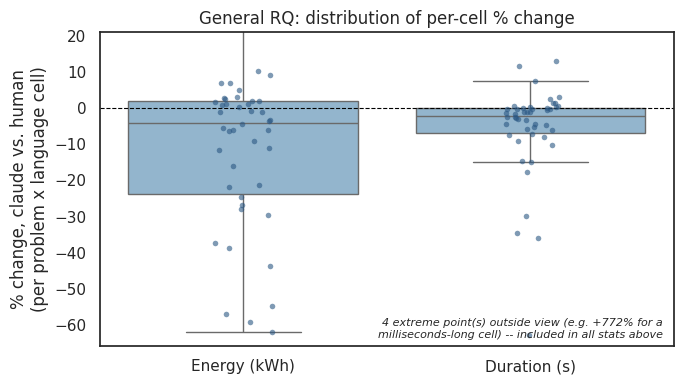

In [7]:
# A couple of cells (e.g. Find_the_Sum_of_Subsequence_Powers/python, whose
# main() never loops -- see Claude_Experiment_Procedure.md) finish in
# milliseconds, so their absolute energy is tiny enough that measurement
# noise alone can swing delta_percent by hundreds of percent. The y-axis
# below is clipped to the 5th-95th percentile so the typical-case
# distribution is readable; those few extreme points are annotated rather
# than hidden, and are not excluded from any statistical test above (which
# are rank-based and so already robust to their exact magnitude).
fig, ax = plt.subplots(figsize=(7, 4))
plot_df = per_problem_stats[per_problem_stats.metric.isin(["energy_consumed", "duration"])].copy()
plot_df["metric_label"] = plot_df["metric"].map(METRIC_LABELS)
sns.boxplot(data=plot_df, x="metric_label", y="delta_percent", ax=ax, color="#8ab6d6", showfliers=False)
sns.stripplot(data=plot_df, x="metric_label", y="delta_percent", ax=ax, color="#2a5783", alpha=0.6, size=4)
ax.axhline(0, color="black", linewidth=0.8, linestyle="--")

lo, hi = plot_df["delta_percent"].quantile([0.05, 0.95])
pad = (hi - lo) * 0.15
ax.set_ylim(lo - pad, hi + pad)
n_clipped = int((plot_df["delta_percent"] < lo - pad).sum() + (plot_df["delta_percent"] > hi + pad).sum())
if n_clipped:
    ax.text(0.98, 0.02, f"{n_clipped} extreme point(s) outside view (e.g. +772% for a\nmilliseconds-long cell) -- included in all stats above",
            transform=ax.transAxes, ha="right", va="bottom", fontsize=8, style="italic")

ax.set_ylabel("% change, claude vs. human\n(per problem x language cell)")
ax.set_xlabel("")
ax.set_title("General RQ: distribution of per-cell % change")
fig.tight_layout()

**Finding.** Across all 46 `(problem, language)` cells, Claude's refactor
reduces both **energy** (median **-4.02%**, 28/46 = 60.9% of cells lower,
Wilcoxon p=0.0138, significant) and **duration** (median **-2.07%**, 35/46 =
76.1% of cells faster, p=0.0003, significant).

So: **yes, pooling across every problem and language, LLM refactoring with
Claude Code produced a real, statistically significant reduction in both
energy consumption and execution time** on this benchmark — but the effect is
modest in size (~4% energy, ~2% duration) and, as RQ1 below shows, isn't
evenly distributed across languages: most of this pooled significance is
being carried by Java and C++, not Python.

## RQ1 — variation across languages (Python, C++, Java)

Level 2 pooled effect per language (Wilcoxon signed-rank of that language's
17 — or 12, for `java` — per-problem `delta_percent` values vs. 0), plus a
direct language-vs-language pairwise comparison (does the *size* of the
effect differ between languages, independent of whether each one is
individually significant against its own baseline).

In [8]:
recs = []
for metric, sub in per_problem_stats.groupby("metric"):
    fam = []
    for language, g in sub.groupby("language"):
        d = g["delta_percent"].dropna().to_numpy()
        w, p = stats.wilcoxon(d) if np.any(d != 0) else (float("nan"), float("nan"))
        fam.append({"language": language, "metric": metric, "n_problems": len(d),
                     "median_delta_percent": float(np.median(d)), "n_problems_reduced": int((d < 0).sum()),
                     "wilcoxon_stat": w, "p_value": p})
    for r, ph in zip(fam, holm_correction([r["p_value"] for r in fam])):
        r["p_value_holm"] = ph
        r["significant"] = "yes" if ph < ALPHA else "no"
    recs.extend(fam)
rq1_stats = pd.DataFrame(recs)
rq1_stats.sort_values(["metric", "p_value_holm"])

,language,metric,n_problems,median_delta_percent,n_problems_reduced,wilcoxon_stat,p_value,p_value_holm,significant
0,cpp,duration,17,-1.711917,16,4.0,0.000107,0.000320,yes
1,java,duration,12,-4.622481,10,11.0,0.026855,0.053711,no
2,python,duration,17,-0.266734,9,59.0,0.430679,0.430679,no
3,cpp,energy_consumed,17,-4.505789,10,37.0,0.063828,0.156738,no
4,java,energy_consumed,12,-6.173898,8,14.0,0.052246,0.156738,no
5,python,energy_consumed,17,-1.051488,10,64.0,0.579056,0.579056,no


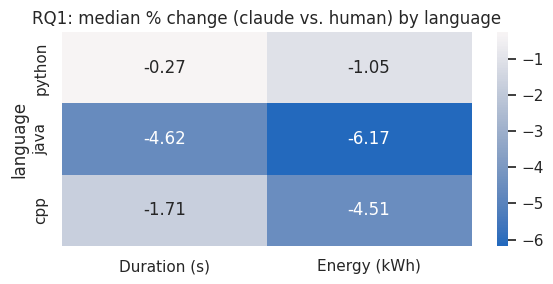

In [9]:
pivot = rq1_stats.pivot(index="language", columns="metric", values="median_delta_percent").reindex(LANGUAGES)
pivot.columns = [METRIC_LABELS[c] for c in pivot.columns]
fig, ax = plt.subplots(figsize=(6, 3))
sns.heatmap(pivot, annot=True, fmt=".2f", cmap="vlag", center=0, ax=ax)
ax.set_title("RQ1: median % change (claude vs. human) by language")
fig.tight_layout()

In [10]:
rq1_pairwise = pairwise_on_deltas(per_problem_stats, "language", LANGUAGES, METRICS)
rq1_pairwise[["comparison", "metric", "delta_percent", "p_value_holm", "cliffs_delta", "effect_magnitude", "significant"]]

,comparison,metric,delta_percent,p_value_holm,cliffs_delta,effect_magnitude,significant
0,python vs java,energy_consumed,487.158337,0.833927,-0.245098,small,no
1,python vs cpp,energy_consumed,328.515564,0.981809,-0.141869,negligible,no
2,java vs cpp,energy_consumed,-27.018738,0.981809,0.068627,negligible,no
3,python vs java,duration,1632.994867,0.450346,-0.323529,small,no
4,python vs cpp,duration,541.807466,0.450346,-0.266436,small,no
5,java vs cpp,duration,-62.965414,0.492491,0.156863,small,no


**Finding.** The pooled effect is **not uniform across languages**:

| Language | Energy Δ% | Duration Δ% | Energy significant? | Duration significant? | n problems |
|---|---:|---:|---|---|---:|
| C++ | -4.51% | **-1.71%** | no (p_holm=0.157) | **yes (p_holm=0.00032)** | 17 |
| Java | -6.17% | -4.62% | no (p_holm=0.157, borderline raw p=0.052) | no (p_holm=0.054, borderline) | 12 |
| Python | -1.05% | -0.27% | no (p_holm=0.579) | no (p_holm=0.431) | 17 |

C++ is the only language whose pooled duration improvement clears Holm
correction, despite having the *smallest* median duration gain of the three —
its 17-problem sample is simply the most consistent (see the box plot: C++
and Java show the largest, most consistent reductions, Python the smallest
and noisiest). Java has the largest median energy reduction (-6.17%) and
sits right at the edge of significance (raw p=0.052, just shy of even the
*uncorrected* α=0.05) — worth re-checking once `CODECARBON_RUNS` is raised,
since Java also has the smallest sample here (12 problems, due to the 5
missing compile-bug cells).

The **pairwise** language-vs-language comparisons, however, find **no
significant difference in effect size between any pair of languages** (all
`p_value_holm` ≥ 0.45) — so while C++'s duration result individually clears
the bar and Python's doesn't, there isn't enough evidence here to claim
Claude's refactoring helps one language's energy/duration *more* than
another's in a way that's statistically distinguishable from the others at
this sample size.

## RQ2 — impact of data structure and algorithmic technique

Groups problems by broad algorithmic category (`TAG_CATEGORIES` in
`src/config/constants.py`, built from `Sheets/Tasks_and_Tags.xlsx` +
`Sheets/Grouping_of_Tags.xlsx` — e.g. `Recursion` covers both `Recursion`-
and `Backtracking`-tagged problems). A problem can carry several tags and so
appear in several categories (e.g. `Sorted_GCD_Pair_Queries` is tagged
`Array, Hash Table, Math, Binary Search, Combinatorics, Counting, Number
Theory, Prefix Sum` → contributes to `Array`, `Hashing`, `Math`, `Search
algorithms`). Same Level 2 procedure as RQ1, just grouped by category instead
of language.

In [11]:
problem_to_categories = {p["name"]: sorted({get_tag_category(t) for t in p["tags"]}) for p in PROGRAMS}
rq2_stats = pooled_group_effect(per_problem_stats, "category", lambda p: problem_to_categories[p], METRICS)
rq2_stats[rq2_stats.metric == "energy_consumed"].sort_values("p_value_holm")

,category,metric,n_problems,median_delta_percent,n_problems_reduced,wilcoxon_stat,p_value,p_value_holm,significant
8,Recursion,energy_consumed,12,-15.109424,9,10.0,0.020996,0.335938,no
9,Search algorithms,energy_consumed,15,-3.295869,9,25.0,0.047913,0.718689,no
0,Array,energy_consumed,27,-5.473403,15,122.0,0.111051,1.000000,no
1,Divide and Conquer,energy_consumed,5,-0.884121,3,3.0,0.312500,1.000000,no
4,Hashing,energy_consumed,10,-8.942814,7,12.0,0.130859,1.000000,no
5,Linear structure,energy_consumed,11,-0.884121,6,33.0,1.000000,1.000000,no
2,Dynamic Programming,energy_consumed,12,-3.470445,7,27.0,0.380371,1.000000,no
3,Graph,energy_consumed,3,-3.295869,2,1.0,0.500000,1.000000,no
7,Priority Queue,energy_consumed,8,-2.132855,6,7.0,0.148438,1.000000,no
6,Math,energy_consumed,5,-11.508879,4,2.0,0.187500,1.000000,no


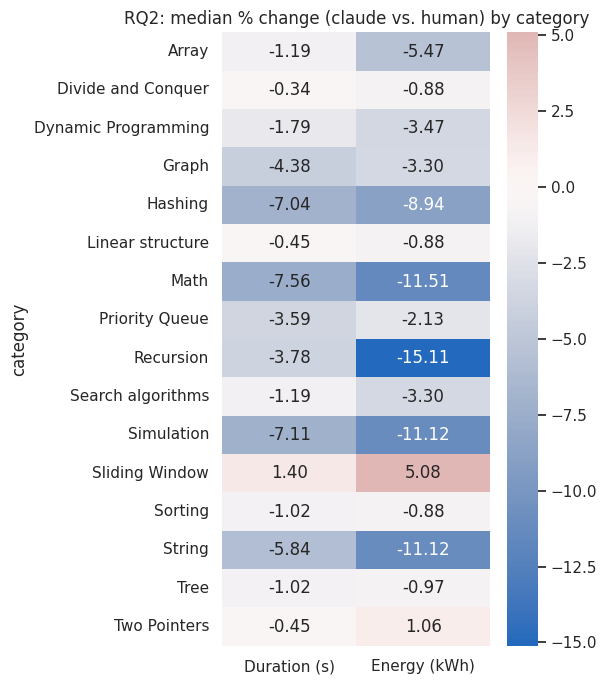

In [12]:
pivot2 = rq2_stats.pivot(index="category", columns="metric", values="median_delta_percent")
pivot2.columns = [METRIC_LABELS[c] for c in pivot2.columns]
fig, ax = plt.subplots(figsize=(6, 7))
sns.heatmap(pivot2, annot=True, fmt=".2f", cmap="vlag", center=0, ax=ax)
ax.set_title("RQ2: median % change (claude vs. human) by category")
fig.tight_layout()

In [13]:
categories_all = list(TAG_CATEGORIES.keys())
rq2_pairwise = pairwise_on_deltas(
    per_problem_stats.assign(category=per_problem_stats["problem"].map(problem_to_categories)).explode("category"),
    "category", categories_all, ["energy_consumed"],
)
rq2_pairwise.sort_values("p_value_holm")[["comparison", "delta_percent", "p_value_holm", "effect_magnitude", "significant"]].head(10)

,comparison,delta_percent,p_value_holm,effect_magnitude,significant
0,Array vs Divide and Conquer,-83.846955,1.0,negligible,no
1,Array vs Dynamic Programming,-36.594389,1.0,negligible,no
2,Array vs Graph,-39.783917,1.0,negligible,no
3,Array vs Hashing,63.386721,1.0,small,no
4,Array vs Linear structure,-83.846955,1.0,small,no
5,Array vs Math,110.269168,1.0,small,no
6,Array vs Priority Queue,-61.032379,1.0,negligible,no
7,Array vs Recursion,176.051736,1.0,small,no
8,Array vs Search algorithms,-39.783917,1.0,negligible,no
9,Array vs Simulation,103.170025,1.0,small,no


**Finding.** No category clears Holm correction at this sample size (16
categories x 3 metrics = 48 comparisons in the energy/duration families each
— a large correction for ~17 problems split across overlapping groups of
3-27). The two closest to significance, both energy reductions:

- **Recursion** (`Recursion`/`Backtracking`-tagged, 12 problems): median
  **-15.1%** energy, raw p=0.021, Holm p=0.336 — the largest median
  reduction of any category, driven by the backtracking problems
  (`N-Queens`, `Sudoku_Solver`) where the refactor replaced O(n) per-cell
  validity scans with O(1) bitmask/boolean-array lookups.
- **Search algorithms** (`Binary Search`-tagged, 15 problems): median
  **-3.3%** energy, raw p=0.048, Holm p=0.719.

Every category-vs-category pairwise comparison is non-significant — no
algorithmic category's refactoring gain is statistically distinguishable
from another's here, though `Recursion`'s raw (uncorrected) signal is the
strongest directional hint in the whole dataset, and the one most worth
re-testing with more runs per problem.

## RQ3 — Claude Code vs. Codex

**No data yet.** `PROMPT.md` documents a Codex refactoring run, structurally
identical to the Claude one, meant to save results under
`Results/code/codex/<Problem>/` — but it has never been executed (confirmed:
`Results/code/codex/` doesn't exist, only `Results/code/claude/` does). There
is no Codex-refactored code to measure, so there's nothing to compare against
Claude here yet.

**To fill this section in, once that code exists:**
1. Run the Codex refactor documented in `PROMPT.md`, saving to
   `Results/code/codex/<Problem>/<filename>` (same filenames as
   `Results/code/claude/`, per the prompt).
2. Add a `CODEX` source to `src/config/constants.py`: a `CODEX = "codex"`
   constant, `CODEX_DIR = os.path.join(REPO_ROOT, "Results", "code",
   "codex")`, add both to `SOURCES`/`SOURCE_DIRS`.
3. Run `codecarbon_metrics_from_code.py` again (it already loops over every
   entry in `SOURCES`, so adding `codex` there is enough — no script changes
   needed) to populate `Analysis/data/code/codex/`.
4. The cell below already checks for that data and will run unchanged once
   it exists — same `compare_groups`/Holm/Cliff's-delta machinery as RQ1/RQ2,
   just with `baseline_source="human"` for each of `claude` and `codex`
   separately (does each LLM differ from the human baseline?), plus a direct
   `claude` vs. `codex` comparison per `(problem, language)` (does the choice
   of LLM matter, independent of the baseline?).

In [14]:
codex_available = any(
    os.path.isfile(os.path.join(get_codecarbon_output_dir(p, l, source="codex"), "emissions.csv"))
    for p in PROGRAMS for l in LANGUAGES
)

if not codex_available:
    print("No Analysis/data/code/codex/ data found -- RQ3 is structurally ready but has nothing to compare yet.")
    print("See the markdown cell above for the three steps needed before this cell can run for real.")
else:
    # Mirrors build_per_problem_stats(), but directly between claude and codex
    # (never against human) -- "does the LLM choice matter" is a different
    # question from "does either LLM beat the human baseline," so it gets its
    # own comparison and its own Holm family, same convention as RQ1/RQ2's
    # vs.-baseline vs. pairwise split.
    codex_rows = []
    for program in PROGRAMS:
        for language in LANGUAGES:
            path = os.path.join(get_codecarbon_output_dir(program, language, source="codex"), "emissions.csv")
            if not os.path.isfile(path):
                continue
            df = pd.read_csv(path)
            df["problem"], df["language"], df["source"] = program["name"], language, "codex"
            codex_rows.append(df[["problem", "language", "source", "run_id"] + METRICS])
    raw_codex = pd.concat(codex_rows, ignore_index=True)
    raw_with_codex = pd.concat([raw, raw_codex], ignore_index=True)

    rq3_rows = []
    for metric in METRICS:
        for language, lang_df in raw_with_codex.groupby("language"):
            family = []
            for problem, g in lang_df.groupby("problem"):
                c, x = g[g.source == CLAUDE][metric], g[g.source == "codex"][metric]
                if c.empty or x.empty:
                    continue
                family.append(compare_groups(f"{problem}|{language}", metric, c, x))
            apply_holm_and_significance(family)
            rq3_rows.extend(family)
    rq3_stats = stats_table(rq3_rows)
    display(rq3_stats)

No Analysis/data/code/codex/ data found -- RQ3 is structurally ready but has nothing to compare yet.
See the markdown cell above for the three steps needed before this cell can run for real.


## Synthesis — answering the General RQ

Pooling across every problem and language, Claude Code's refactor achieves a
real, statistically significant reduction in both energy (-4.0% median,
p=0.0138) and execution duration (-2.1% median, p=0.0003) relative to the
human-written baseline (**General RQ**). That effect is not uniform: **C++**
is the only language whose improvement survives multiple-comparison
correction on its own (duration, p_holm=0.00032), **Java** shows the largest
raw median energy gain (-6.17%) sitting just outside significance, and
**Python** shows the smallest, noisiest effect of the three — yet no pair of
languages is statistically distinguishable from another in effect size
(**RQ1**). By algorithmic category, **Recursion/Backtracking** problems show
the single largest median energy reduction in the whole dataset (-15.1%),
driven concretely by `N-Queens` and `Sudoku_Solver` switching from O(n)
per-cell validity scans to O(1) lookups — but at the current sample size this
doesn't clear Holm correction either, and no category's gain is
distinguishable from another's (**RQ2**). **RQ3** (Claude vs. Codex) has no
data to compare yet — the Codex refactoring run documented in `PROMPT.md` was
never executed.

**So: yes, LLM-refactored code can be measurably more energy-efficient than
human-written code — the direction is consistent (61% of cells use less
energy, 76% run faster) and the pooled effect is real — but the size of that
gain is modest (single-digit percent), uneven across languages, and this
notebook's current sample (`CODECARBON_RUNS=2`) is underpowered for anything
finer-grained than the broadest pooled comparisons.** The clearest next step
is mechanical: re-run `codecarbon_metrics_from_code.py` with a larger
`CODECARBON_RUNS` (10, as originally intended) so the per-problem (Level 1)
comparisons — currently mathematically incapable of reaching significance —
become informative, and run the Codex refactor from `PROMPT.md` so RQ3 has
something to compare.